# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [3]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()
df.duplicated().sum()

np.int64(720)

In [4]:
df.isna().sum()

Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

In [5]:
df["MSRP"].value_counts().head()

MSRP
2000     1036
25995      19
29995      19
20995      16
27995      16
Name: count, dtype: int64

In [6]:
df[df["Engine HP"].isna()]["Engine Fuel Type"].value_counts(dropna=False)

Engine Fuel Type
electric                            44
regular unleaded                    14
flex-fuel (unleaded/natural gas)     6
premium unleaded (recommended)       4
diesel                               1
Name: count, dtype: int64

In [7]:
df.nlargest(3, "highway MPG")

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
1119,Audi,A6,2017,premium unleaded (recommended),252.0,4.0,AUTOMATED_MANUAL,front wheel drive,4.0,Midsize,Sedan,354,24,3105,51600
5790,BMW,i3,2015,electric,170.0,0.0,DIRECT_DRIVE,rear wheel drive,4.0,Compact,4dr Hatchback,111,137,3916,42400
5791,BMW,i3,2016,electric,170.0,0.0,DIRECT_DRIVE,rear wheel drive,4.0,Compact,4dr Hatchback,111,137,3916,42400


In [8]:
df.groupby("Engine Fuel Type")["highway MPG"].describe()

,count,mean,std,min,25%,50%,75%,max
Engine Fuel Type,,,,,,,,
diesel,154.0,36.564935,6.743601,20.0,30.0,39.0,42.00,46.0
electric,66.0,99.590909,9.026418,74.0,97.0,101.0,105.00,111.0
flex-fuel (premium unleaded recommended/E85),26.0,25.346154,6.235013,18.0,18.0,27.5,31.25,33.0
flex-fuel (premium unleaded required/E85),54.0,19.925926,1.746715,17.0,19.0,19.0,20.75,23.0
flex-fuel (unleaded/E85),899.0,22.629588,4.632803,15.0,19.0,22.0,25.00,40.0
flex-fuel (unleaded/natural gas),6.0,25.000000,0.000000,25.0,25.0,25.0,25.00,25.0
natural gas,2.0,38.000000,0.000000,38.0,38.0,38.0,38.00,38.0
premium unleaded (recommended),1523.0,28.672357,9.363849,16.0,25.0,29.0,31.00,354.0
premium unleaded (required),2009.0,23.896964,5.125403,12.0,20.0,24.0,27.00,48.0


In [9]:
df["Transmission Type"].value_counts()

Transmission Type
AUTOMATIC           8266
MANUAL              2935
AUTOMATED_MANUAL     626
DIRECT_DRIVE          68
UNKNOWN               19
Name: count, dtype: int64

In [10]:
df.groupby(["Make", "Model"])["Popularity"].nunique().value_counts()

Popularity
1    928
Name: count, dtype: int64

In [11]:
(df.groupby(["Make", "Model", "Year"])["Vehicle Size"].nunique() > 1).sum()

np.int64(76)

**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | `df.duplicated().sum()` | 720 | `drop_duplicates()`: 11,914 rows became 11,194 | The same listing counted twice would inflate counts and averages. |
| 2 | MSRP of exactly $2,000 | `value_counts()`: $2,000 is the most common price by far (1,036 raw rows; the next most common appears 19 times). All of them are 1990–2000 cars. | 747 | Set to NaN | A flat $2,000 is a 'no price' code, not a real price. I also flagged other 1990–2000 prices of about $2k–$3k as too low for those models, but I left them in. |
| 3 | Electric cars report MPGe, not MPG | Electric cars show 74–111 'MPG' vs a median of 25 for gas cars (`groupby` on fuel type) | 66 | Highway and city MPG set to NaN for electric cars | MPGe measures energy equivalence, not miles per gallon, so averaging it with gas cars would inflate the numbers. |
| 4 | Impossible MPG value | `nlargest` on highway MPG: a 2017 Audi A6 shows 354 (city MPG 24) | 1 | Highway MPG set to NaN | I can't know the real value, so I didn't guess. After this, the highest remaining highway MPG is 53. |
| 5 | Missing values and an UNKNOWN placeholder | `isna().sum()`: Engine HP 69 (44 of them electric cars), Engine Cylinders 30, Number of Doors 6, Fuel Type 3. Transmission 'UNKNOWN' appears 12 times after dedupe. | 108 blanks + 12 UNKNOWN | Blanks left as NaN; UNKNOWN set to NaN | Missing HP is mostly electric cars with no engine, so it's structural rather than a typo. Dropping these rows would also throw away good MSRP and MPG values. |
| 6 | Columns vary at a different level than expected | Popularity has one value for every make+model (928 of 928). Vehicle Size changes within the same model year for 76 model-years. | All rows (Popularity); 495 (Vehicle Size) | Flagged, not changed | Popularity is a model-level score, so it shouldn't be used to compare trims. Size changes within a model year may reflect different body styles, so I used size as labeled and noted it as a limitation. |

In [12]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [13]:
clean = clean.drop_duplicates()
clean.loc[clean["msrp"] == 2000, "msrp"] = np.nan
clean.loc[clean["transmission_type"] == "UNKNOWN", "transmission_type"] = np.nan
electric = clean["engine_fuel_type"] == "electric"
clean.loc[electric, ["highway_mpg", "city_mpg"]] = np.nan
clean.loc[clean["highway_mpg"] == 354, "highway_mpg"] = np.nan

In [14]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11194, 15)
engine_fuel_type       3
engine_hp             69
engine_cylinders      30
transmission_type     12
number_of_doors        6
highway_mpg           67
city_mpg              66
msrp                 747
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: $44,789
Median MSRP: $31,870


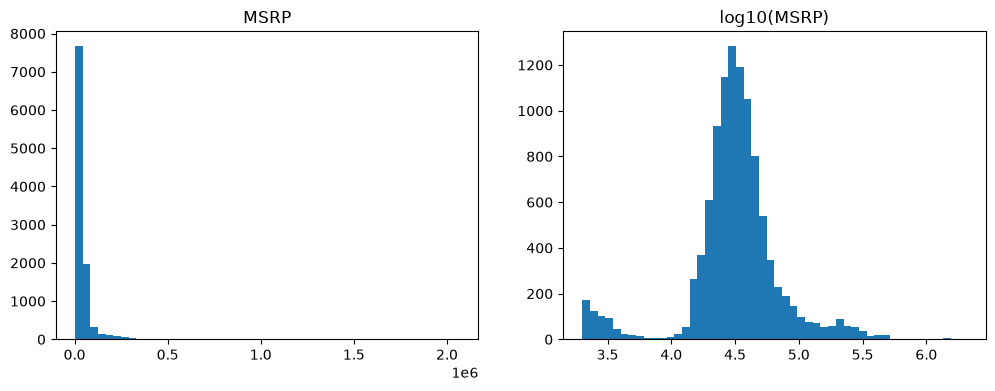

Share above mean: 24.4%


In [15]:
# a) mean and median
print(f"Mean MSRP: ${clean['msrp'].mean():,.0f}")
print(f"Median MSRP: ${clean['msrp'].median():,.0f}")

# b) two histograms side by side (plt.subplots(1, 2))
msrp = clean["msrp"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(msrp, bins=50)
axes[0].set_title("MSRP")
axes[1].hist(np.log10(msrp), bins=50)
axes[1].set_title("log10(MSRP)")
plt.show()

# c) share of cars above the mean
print(f"Share above mean: {(msrp > msrp.mean()).mean():.1%}")

**Answer:** The mean ($44,789) sits well above the median ($31,870) because a few very expensive cars pull it up. The MSRP histogram is heavily right-skewed, and the log version is closer to bell-shaped around $30k, with a small bump of cheap older cars on the left. Only 24.4% of cars cost more than the mean, so the median is the honest number for the homepage.

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [16]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
mpg_2017 = clean[clean["year"] == 2017]
size_stats = mpg_2017.groupby("vehicle_size")["highway_mpg"].agg(["mean", "std"])
print(size_stats)

# b) z = (value - class mean) / class std
civic_z = (42 - size_stats.loc["Compact", "mean"]) / size_stats.loc["Compact", "std"]
s90_z = (34 - size_stats.loc["Large", "mean"]) / size_stats.loc["Large", "std"]
print(f"Civic z-score: {civic_z:.2f}")
print(f"S90 z-score: {s90_z:.2f}")

                   mean       std
vehicle_size                     
Compact       30.880157  6.045381
Large         22.991453  3.491184
Midsize       29.410658  5.452292
Civic z-score: 1.84
S90 z-score: 3.15


**Answer:** The S90 is more impressive for its class: its z-score is 3.15 versus 1.84 for the Civic, so its 34 mpg sits about 3 standard deviations above a typical large car (roughly the top 0.1%), while the Civic is in roughly the top 3%. The data also labels the 42-mpg Civic as Midsize, not Compact (Compact Civics top out at 41 mpg), and against Midsize its z-score is 2.31, which still trails the S90.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

Median 2017 MSRP: $36,738


95% interval: $35,940 to $37,683


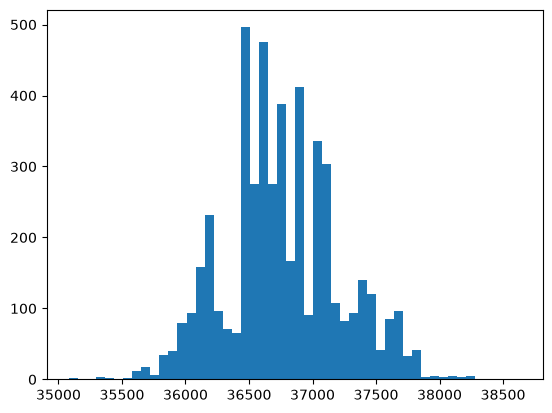

Lincoln 2017 cars: 46
95% interval: $41,648 to $49,025
Width, all 2017: $1,743; Lincoln: $7,378


In [17]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    medians = []
    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))
    return np.array(medians)

# a, b)
prices_2017 = clean.loc[clean["year"] == 2017, "msrp"].dropna()
print(f"Median 2017 MSRP: ${prices_2017.median():,.0f}")
medians = bootstrap_median(prices_2017.values)
low, high = np.percentile(medians, [2.5, 97.5])
print(f"95% interval: ${low:,.0f} to ${high:,.0f}")
plt.hist(medians, bins=50)
plt.show()

# c)
lincoln_2017 = clean.loc[(clean["year"] == 2017) & (clean["make"] == "Lincoln"), "msrp"].dropna()
print(f"Lincoln 2017 cars: {len(lincoln_2017)}")
lincoln_medians = bootstrap_median(lincoln_2017.values)
lincoln_low, lincoln_high = np.percentile(lincoln_medians, [2.5, 97.5])
print(f"95% interval: ${lincoln_low:,.0f} to ${lincoln_high:,.0f}")
print(f"Width, all 2017: ${high - low:,.0f}; Lincoln: ${lincoln_high - lincoln_low:,.0f}")

**Answer:** The Lincoln interval is about 4 times wider ($7,378 vs $1,743) because 46 cars pin down the median less precisely than all 2017 cars, so smaller samples give wider intervals. For the manager: the median 2017 car lists at about $36,700, and a different set of 2017 cars would most likely produce a median between $35,940 and $37,683.

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

n = 509, mean = 30.88


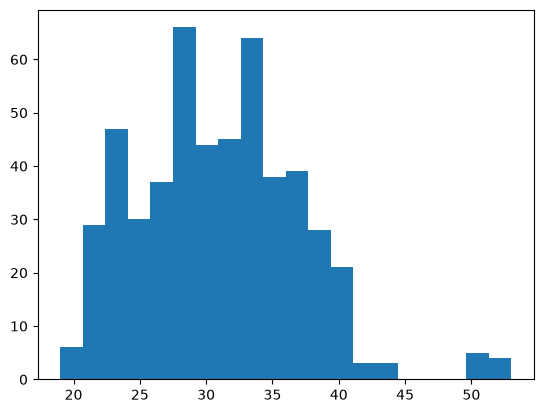

t-statistic: 3.2847
p-value: 0.0005
make        model   
Toyota      Tacoma      27
Chevrolet   Corvette    24
Nissan      Frontier    22
            370Z        17
Porsche     911         14
Honda       Civic       13
Audi        A3          12
Volkswagen  Golf GTI    10
Nissan      Juke        10
Chevrolet   Sonic       10
dtype: int64
Models: 85
t-statistic: 2.5773
p-value: 0.0059


In [18]:
# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram
compact_2017 = clean[(clean["year"] == 2017) & (clean["vehicle_size"] == "Compact")].dropna(subset=["highway_mpg"])
print(f"n = {len(compact_2017)}, mean = {compact_2017['highway_mpg'].mean():.2f}")
plt.hist(compact_2017["highway_mpg"], bins=20)
plt.show()

# c) one-sample t-test vs 30
result = stats.ttest_1samp(compact_2017["highway_mpg"], 30, alternative="greater")
print(f"t-statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")

# d) rows per make+model, then one row per model and retest
rows_per_model = compact_2017.groupby(["make", "model"]).size().sort_values(ascending=False)
print(rows_per_model.head(10))
print(f"Models: {len(rows_per_model)}")
per_model = compact_2017.groupby(["make", "model"])["highway_mpg"].mean()
result_model = stats.ttest_1samp(per_model, 30, alternative="greater")
print(f"t-statistic: {result_model.statistic:.4f}")
print(f"p-value: {result_model.pvalue:.4f}")

**Answer:** H₀: 2017 compacts average 30 MPG or less; Hₐ: they average more than 30 (one-sided, since the claim is 'over 30'). The sample of 509 cars has no extreme skew or outliers, so a t-test is fine, and it gives p = 0.0005; but the rows repeat models (Tacoma alone has 27), so the one-row-per-model test (p = 0.006) is more trustworthy, and it still supports the claim with a small margin of about 0.9 MPG.

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [19]:
# a) compare median MSRP by transmission type
auto_manual = clean[clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])]
print(auto_manual.groupby("transmission_type")["msrp"].median())

# b) compare year by transmission type
print(auto_manual.groupby("transmission_type")["year"].agg(["mean", "median"]))

# c) compare 2015-2017 medians overall and within each vehicle_size
# For 2015-17 compacts, test automatic vs manual prices with:
# stats.mannwhitneyu(auto, manual)
recent = auto_manual[(auto_manual["year"] >= 2015) & (auto_manual["year"] <= 2017)]
print(recent.groupby("transmission_type")["msrp"].median())
print(recent.groupby(["vehicle_size", "transmission_type"])["msrp"].median())

compact_recent = recent[recent["vehicle_size"] == "Compact"]
auto = compact_recent.loc[compact_recent["transmission_type"] == "AUTOMATIC", "msrp"].dropna()
manual = compact_recent.loc[compact_recent["transmission_type"] == "MANUAL", "msrp"].dropna()
result = stats.mannwhitneyu(auto, manual)
print(f"p-value: {result.pvalue:.4f}")

transmission_type
AUTOMATIC    33620.0
MANUAL       21875.0
Name: msrp, dtype: float64
                          mean  median
transmission_type                     
AUTOMATIC          2011.843340  2015.0
MANUAL             2006.475503  2008.0
transmission_type
AUTOMATIC    37065.0
MANUAL       26905.0
Name: msrp, dtype: float64
vehicle_size  transmission_type
Compact       AUTOMATIC            25995.0
              MANUAL               25860.0
Large         AUTOMATIC            44400.0
              MANUAL               38395.0
Midsize       AUTOMATIC            37980.0
              MANUAL               26920.0
Name: msrp, dtype: float64
p-value: 0.2048


**Answer:** The raw gap is large (median $33,620 automatic vs $21,875 manual), but manuals are older (median year 2008 vs 2015) and most of them are compacts. Among 2015–17 compacts, prices are essentially the same ($25,995 vs $25,860, Mann–Whitney p = 0.20), though midsize and large manuals still list about $11k and $6k lower, so model mix needs checking. Sentence for the rep: 'Manuals aren't clearly cheaper for comparable 2015–17 compacts, so I wouldn't push them to budget shoppers on price until the midsize gap is checked.'

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [20]:
# a) Welch t-test, 4-door vs 2-door
mpg = clean.dropna(subset=["highway_mpg"])
four_door = mpg.loc[mpg["number_of_doors"] == 4, "highway_mpg"]
two_door = mpg.loc[mpg["number_of_doors"] == 2, "highway_mpg"]
print(f"Difference in means: {four_door.mean() - two_door.mean():.2f} mpg")
result = stats.ttest_ind(four_door, two_door, equal_var=False)
print(f"p-value: {result.pvalue:.6f}")

# b) yearly gas cost = miles * price_per_gallon / mpg
miles, price_per_gallon = 12000, 3.50
cost_2door = miles * price_per_gallon / two_door.mean()
cost_4door = miles * price_per_gallon / four_door.mean()
print(f"Yearly gas cost, 2-door: ${cost_2door:,.0f}")
print(f"Yearly gas cost, 4-door: ${cost_4door:,.0f}")
print(f"Savings with 4-door: ${cost_2door - cost_4door:,.0f} per year")

# c) simulation
n_sims, hits = 1000, 0
for _ in range(n_sims):
    # sample 30 from each group with rng.choice(..., 30, replace=False), run the test, count p < 0.05
    sample_4 = rng.choice(four_door, 30, replace=False)
    sample_2 = rng.choice(two_door, 30, replace=False)
    if stats.ttest_ind(sample_4, sample_2, equal_var=False).pvalue < 0.05:
        hits += 1
print(f"Share significant: {hits / n_sims:.1%}")

Difference in means: 1.55 mpg
p-value: 0.000000
Yearly gas cost, 2-door: $1,663
Yearly gas cost, 4-door: $1,567
Savings with 4-door: $96 per year


Share significant: 15.0%


**Answer:** 4-door cars average 1.55 mpg more on the highway (p < 0.001), which works out to about $96 a year less in gas than a 2-door car at 12,000 miles and $3.50/gallon. Only 15% of 30-car samples detect that gap, so the 'significant' result comes from the large sample, not from a large effect. I wouldn't use 'significantly more fuel-efficient' in an ad; I'd say 'about 1.5 mpg better on the highway, roughly $100 a year in gas.'

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:** Manual cars don't clearly cost less: the raw median gap ($33,620 automatic vs $21,875 manual) mostly reflects that manuals are older and mostly compacts, and among 2015–17 compacts the prices are essentially the same. Horsepower tracks price closely (correlation 0.82, where 1.0 would be a perfect match), so engine power is a stronger pricing signal than the gearbox. Transmission is also tied to size (about 34% of 2015–17 compacts are manual vs under 2% of large cars), which is why the raw comparison misleads. One limitation: MSRP is the manufacturer's list price rather than what cars actually sold for, and listings before 2001 look unreliable (many around $2,000–$3,000), so the all-years figures are weaker than the recent ones.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

Pearson: 0.650
Pearson with log10(msrp): 0.698
Spearman: 0.822


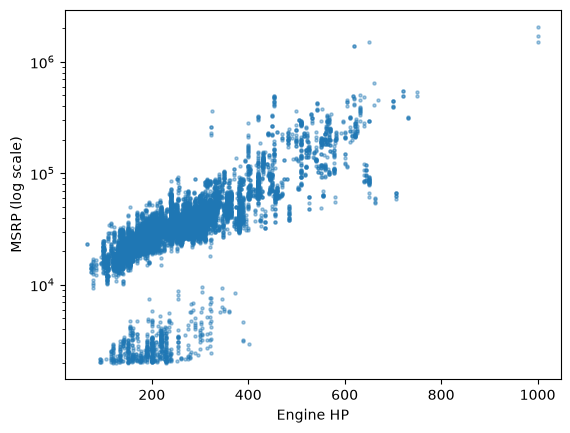

In [21]:
# S1
hp_price = clean[["engine_hp", "msrp"]].dropna()
print(f"Pearson: {hp_price['engine_hp'].corr(hp_price['msrp']):.3f}")
print(f"Pearson with log10(msrp): {hp_price['engine_hp'].corr(np.log10(hp_price['msrp'])):.3f}")
print(f"Spearman: {hp_price['engine_hp'].corr(hp_price['msrp'], method='spearman'):.3f}")
plt.scatter(hp_price["engine_hp"], hp_price["msrp"], s=5, alpha=0.4)
plt.yscale("log")
plt.xlabel("Engine HP")
plt.ylabel("MSRP (log scale)")
plt.show()

**Answer:** Spearman (0.82) is highest because the horsepower–price relationship consistently rises but curves, and Spearman uses ranks, so the few $1M+ cars don't dominate; Pearson (0.65) is pulled down by those extreme prices, and logging the price lifts it to 0.70. Horsepower doesn't prove causation: a lurking variable is brand, since luxury makers both build high-horsepower engines and charge more for everything.

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [22]:
# S2
table = pd.crosstab(recent["vehicle_size"], recent["transmission_type"])
print(table)
chi2, p_value, dof, expected = stats.chi2_contingency(table)
print(f"chi-square: {chi2:.2f}, p-value: {p_value:.4f}")

transmission_type  AUTOMATIC  MANUAL
vehicle_size                        
Compact                 1119     589
Large                   1473      26
Midsize                 1919     198
chi-square: 756.93, p-value: 0.0000


**Answer:** The crosstab shows transmission depends on size (chi-square = 757, p < 0.001): 589 of 1,708 compacts (about 34%) are manual versus 26 of 1,499 large cars (under 2%). That connects to Q6, because most manuals are compacts, which are the cheapest class, so the raw manual-vs-automatic price gap partly reflects vehicle size.